<a href="https://colab.research.google.com/github/aong2hehms/DL_Session7/blob/main/Tugas_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Tahap 1

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [3]:
#Menentukan device gpu
device = torch.device("cuda" if torch.cuda.is_available()else "cpu")
print("Device: ",device)

Device:  cpu


In [4]:
#Load data
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform = transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root = './data',
    train = False,
    download = True,
    transform = transform
)
train_Loader = DataLoader(
    train_dataset,
    batch_size = 64,
    shuffle = True

)

test_loader = DataLoader(
    test_dataset,
    batch_size = 64,
    shuffle= False
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.6MB/s]


In [13]:
#membuat arsitektur MLPClassifier
class MLPClassifier(nn.Module):
    def __init__(self):
        super(MLPClassifier, self).__init__()

        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), 784)

        x = self.relu(self.fc1(x))
        z = self.relu(self.fc2(x))

        x = self.fc3(z)

        return x, z

In [14]:
#inisialisasi model
model = MLPClassifier().to(device)
criterion =  nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr = 0.001
)

In [ ]:
# Training model
epochs =30

for epochs in range(epochs):
  model.train()

  total_loss=0

  for images,labels in train_Loader:
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()
    outputs, z = model(images)

    loss = criterion (outputs,labels)
    loss.backward()

    optimizer.step()
    total_loss += loss.item()

    print(
        f"epoch [{epochs+1}/{epochs}],"
        f'loss: {total_loss/len(train_Loader):.4f}'
    )

Streaming output truncated to the last 5000 lines.
epoch [25/24],loss: 0.0264
epoch [25/24],loss: 0.0266
epoch [25/24],loss: 0.0267
epoch [25/24],loss: 0.0269
epoch [25/24],loss: 0.0270
epoch [25/24],loss: 0.0271
epoch [25/24],loss: 0.0272
epoch [25/24],loss: 0.0273
epoch [25/24],loss: 0.0275
epoch [25/24],loss: 0.0276
epoch [25/24],loss: 0.0276
epoch [25/24],loss: 0.0280
epoch [25/24],loss: 0.0281
epoch [25/24],loss: 0.0282
epoch [25/24],loss: 0.0283
epoch [25/24],loss: 0.0284
epoch [25/24],loss: 0.0285
epoch [25/24],loss: 0.0286
epoch [25/24],loss: 0.0288
epoch [25/24],loss: 0.0289
epoch [25/24],loss: 0.0291
epoch [25/24],loss: 0.0293
epoch [25/24],loss: 0.0295
epoch [25/24],loss: 0.0297
epoch [25/24],loss: 0.0298
epoch [25/24],loss: 0.0300
epoch [25/24],loss: 0.0301
epoch [25/24],loss: 0.0302
epoch [25/24],loss: 0.0303
epoch [25/24],loss: 0.0303
epoch [25/24],loss: 0.0305
epoch [25/24],loss: 0.0307
epoch [25/24],loss: 0.0307
epoch [25/24],loss: 0.0308
epoch [25/24],loss: 0.0309
epoc

In [64]:
#Evaluasi
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs, z = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 88.85%


In [65]:
#simpan bobot matrix
W1 = model.fc1.weight.data.cpu().clone()
W2 = model.fc2.weight.data.cpu().clone()
W3 = model.fc3.weight.data.cpu().clone()

torch.save({
    "W1": W1,
    "W2": W2,
    "W3": W3
}, "mlp_weights.pth")

#Tahap 2

In [74]:
#One hot factor class
import torch.nn.functional as F

target_class = 1

y = F.one_hot(
    torch.tensor(target_class),
    num_classes=10
).float()

print(y)

tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0.])


In [75]:
with torch.no_grad():
  z_hat = F.relu(W3.T @y)
  h1_hat = F.relu(W2.T @z_hat)
  x_hat = torch.sigmoid(W1.T @h1_hat)

print("z_hat:", z_hat.shape)
print("h1_hat:", h1_hat.shape)
print("x_hat:", x_hat.shape)

z_hat: torch.Size([64])
h1_hat: torch.Size([256])
x_hat: torch.Size([784])


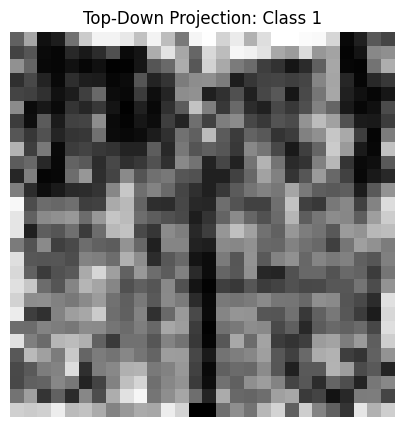

In [76]:
import matplotlib.pyplot as plt

image = x_hat.reshape(28, 28).numpy()

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title(f"Top-Down Projection: Class {target_class}")
plt.axis("off")
plt.show()

#Tahap 3

In [77]:
#Ekstrak lantent fitur
model.eval()
images,labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
  outputs,zMLP = model(images)

print("Original Images:", images.shape)
print("Latent Features:", zMLP.shape)

Original Images: torch.Size([64, 1, 28, 28])
Latent Features: torch.Size([64, 64])


In [79]:
#Proyeksi balik menggunakan Transpose
with torch.no_grad():

    z = zMLP.cpu()

    h1_hat = F.relu(z @ W2)

    x_hat = torch.sigmoid(h1_hat @ W1)

print("Reconstructed Shape:", x_hat.shape)

Reconstructed Shape: torch.Size([64, 784])


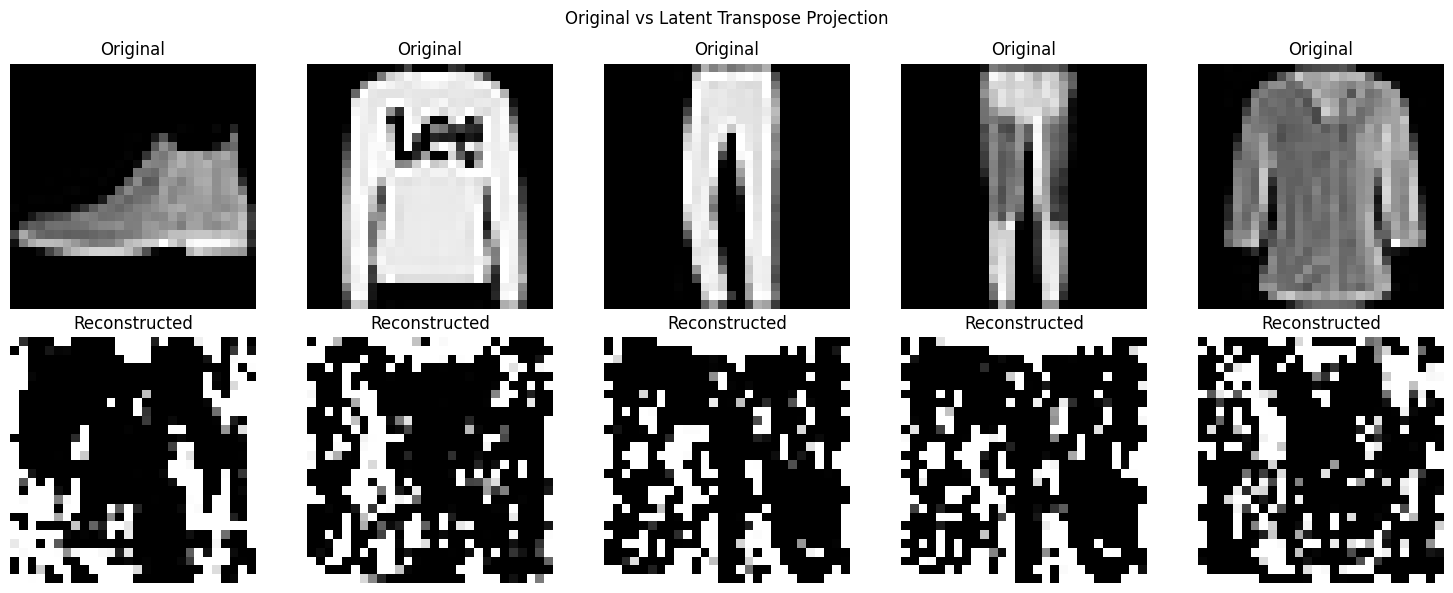

In [81]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):

    original = images[i].cpu().squeeze().numpy()

    reconstructed = x_hat[i].reshape(28, 28).numpy()

    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed, cmap="gray")
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.suptitle("Original vs Latent Transpose Projection")
plt.tight_layout()
plt.show()

In [83]:
#Perbedaan MSE
original = images.cpu().view(-1, 784)

mse = torch.mean((original - x_hat) ** 2)

print("Reconstruction MSE:", mse.item())

Reconstruction MSE: 0.3127988874912262


#Tahap 4

In [84]:
# Membekukan seluruh parameter MLP
for param in model.parameters():
    param.requires_grad = False

model.eval()

print("MLP Classifier Frozen!")

MLP Classifier Frozen!


In [86]:
def extract_latent(model, loader):

    latent_data = []
    original_data = []

    model.eval()

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs, z = model(images)

            latent_data.append(z.cpu())
            original_data.append(
                images.view(images.size(0), 784).cpu()
            )

    return (
        torch.cat(latent_data),
        torch.cat(original_data)
    )


z_train, x_train = extract_latent(model, train_Loader)

z_test, x_test = extract_latent(model, test_loader)

print("Training Latent:", z_train.shape)
print("Testing Latent:", z_test.shape)

Training Latent: torch.Size([60000, 64])
Testing Latent: torch.Size([10000, 64])


In [87]:
#Membuat decoder baru MLP
class MLPDecoder(nn.Module):

    def __init__(self):
        super(MLPDecoder, self).__init__()

        self.fc1 = nn.Linear(64, 256)
        self.fc2 = nn.Linear(256, 784)

        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, z):

        x = self.relu(self.fc1(z))
        x = self.sigmoid(self.fc2(x))

        return x

In [88]:
#Training
decoder = MLPDecoder().to(device)

criterion = nn.MSELoss()

optimizer = optim.Adam(
    decoder.parameters(),
    lr=0.001
)

epochs = 30
batch_size = 64

for epoch in range(epochs):

    decoder.train()

    total_loss = 0

    for i in range(0, len(z_train), batch_size):

        z_batch = z_train[i:i+batch_size].to(device)
        x_batch = x_train[i:i+batch_size].to(device)

        optimizer.zero_grad()

        reconstructed = decoder(z_batch)

        loss = criterion(reconstructed, x_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / (
        (len(z_train) + batch_size - 1) // batch_size
    )

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {avg_loss:.6f}"
    )

Epoch [1/30], Loss: 0.032096
Epoch [2/30], Loss: 0.023785
Epoch [3/30], Loss: 0.022065
Epoch [4/30], Loss: 0.021159
Epoch [5/30], Loss: 0.020591
Epoch [6/30], Loss: 0.020188
Epoch [7/30], Loss: 0.019887
Epoch [8/30], Loss: 0.019652
Epoch [9/30], Loss: 0.019459
Epoch [10/30], Loss: 0.019300
Epoch [11/30], Loss: 0.019167
Epoch [12/30], Loss: 0.019054
Epoch [13/30], Loss: 0.018957
Epoch [14/30], Loss: 0.018871
Epoch [15/30], Loss: 0.018795
Epoch [16/30], Loss: 0.018732
Epoch [17/30], Loss: 0.018670
Epoch [18/30], Loss: 0.018616
Epoch [19/30], Loss: 0.018567
Epoch [20/30], Loss: 0.018522
Epoch [21/30], Loss: 0.018480
Epoch [22/30], Loss: 0.018439
Epoch [23/30], Loss: 0.018404
Epoch [24/30], Loss: 0.018369
Epoch [25/30], Loss: 0.018339
Epoch [26/30], Loss: 0.018307
Epoch [27/30], Loss: 0.018280
Epoch [28/30], Loss: 0.018251
Epoch [29/30], Loss: 0.018227
Epoch [30/30], Loss: 0.018202


In [89]:
#Vannila encoder
class VanillaAutoencoder(nn.Module):

    def __init__(self):
        super(VanillaAutoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):

        z = self.encoder(x)

        reconstructed = self.decoder(z)

        return reconstructed, z

In [92]:
#training vanila encoder
autoencoder = VanillaAutoencoder().to(device)

criterion_ae = nn.MSELoss()

optimizer_ae = optim.Adam(
    autoencoder.parameters(),
    lr=0.001
)

epochs = 30

for epoch in range(epochs):

    autoencoder.train()

    total_loss = 0

    for images, labels in train_Loader:

        images = images.to(device)

        images = images.view(images.size(0), 784)

        optimizer_ae.zero_grad()

        reconstructed, z = autoencoder(images)

        loss = criterion_ae(reconstructed, images)

        loss.backward()

        optimizer_ae.step()

        total_loss += loss.item()

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {total_loss/len(train_Loader):.6f}"
    )

Epoch [1/30], Loss: 0.027176
Epoch [2/30], Loss: 0.015130
Epoch [3/30], Loss: 0.012870
Epoch [4/30], Loss: 0.011562
Epoch [5/30], Loss: 0.010714
Epoch [6/30], Loss: 0.010085
Epoch [7/30], Loss: 0.009598
Epoch [8/30], Loss: 0.009253
Epoch [9/30], Loss: 0.008993
Epoch [10/30], Loss: 0.008771
Epoch [11/30], Loss: 0.008606
Epoch [12/30], Loss: 0.008471
Epoch [13/30], Loss: 0.008331
Epoch [14/30], Loss: 0.008234
Epoch [15/30], Loss: 0.008129
Epoch [16/30], Loss: 0.008058
Epoch [17/30], Loss: 0.007983
Epoch [18/30], Loss: 0.007913
Epoch [19/30], Loss: 0.007848
Epoch [20/30], Loss: 0.007797
Epoch [21/30], Loss: 0.007748
Epoch [22/30], Loss: 0.007708
Epoch [23/30], Loss: 0.007668
Epoch [24/30], Loss: 0.007622
Epoch [25/30], Loss: 0.007585
Epoch [26/30], Loss: 0.007559
Epoch [27/30], Loss: 0.007520
Epoch [28/30], Loss: 0.007497
Epoch [29/30], Loss: 0.007470
Epoch [30/30], Loss: 0.007447


In [93]:
!pip install -q scikit-image

In [94]:
#fungsi evaluasi
import numpy as np
from skimage.metrics import structural_similarity as ssim

def evaluate_model(original, reconstructed):

    original = original.reshape(-1, 1, 28, 28).numpy()

    reconstructed = reconstructed.reshape(-1, 1, 28, 28).numpy()

    mse_values = []
    psnr_values = []
    ssim_values = []

    for i in range(len(original)):

        img_original = original[i, 0]
        img_reconstructed = reconstructed[i, 0]

        mse = np.mean(
            (img_original - img_reconstructed) ** 2
        )

        psnr = 10 * np.log10(1.0 / max(mse, 1e-10))

        ssim_value = ssim(
            img_original,
            img_reconstructed,
            data_range=1.0
        )

        mse_values.append(mse)
        psnr_values.append(psnr)
        ssim_values.append(ssim_value)

    return {
        "MSE": np.mean(mse_values),
        "PSNR": np.mean(psnr_values),
        "SSIM": np.mean(ssim_values)
    }

In [96]:
decoder.eval()

with torch.no_grad():

    reconstructed_mlp = []

    for i in range(0, len(z_test), 64):

        z_batch = z_test[i:i+64].to(device)

        output = decoder(z_batch)

        reconstructed_mlp.append(output.cpu())

    reconstructed_mlp = torch.cat(reconstructed_mlp)


mlp_metrics = evaluate_model(
    x_test,
    reconstructed_mlp
)

print("Frozen Latent Decoder:", mlp_metrics)

Frozen Latent Decoder: {'MSE': np.float32(0.019153092), 'PSNR': np.float32(18.04019), 'SSIM': np.float64(0.6518705046511238)}


In [97]:
autoencoder.eval()

with torch.no_grad():

    reconstructed_ae = []

    for i in range(0, len(x_test), 64):

        x_batch = x_test[i:i+64].to(device)

        output, z = autoencoder(x_batch)

        reconstructed_ae.append(output.cpu())

    reconstructed_ae = torch.cat(reconstructed_ae)


ae_metrics = evaluate_model(
    x_test,
    reconstructed_ae
)

print("Vanilla Autoencoder:", ae_metrics)

Vanilla Autoencoder: {'MSE': np.float32(0.007668445), 'PSNR': np.float32(22.238773), 'SSIM': np.float64(0.802152525414462)}


In [98]:
import pandas as pd

results = pd.DataFrame({
    "Metric": ["MSE", "PSNR", "SSIM"],
    "Frozen Latent Decoder": [
        mlp_metrics["MSE"],
        mlp_metrics["PSNR"],
        mlp_metrics["SSIM"]
    ],
    "Vanilla Autoencoder": [
        ae_metrics["MSE"],
        ae_metrics["PSNR"],
        ae_metrics["SSIM"]
    ]
})

print(results.to_string(index=False))

Metric  Frozen Latent Decoder  Vanilla Autoencoder
   MSE               0.019153             0.007668
  PSNR              18.040190            22.238773
  SSIM               0.651871             0.802153


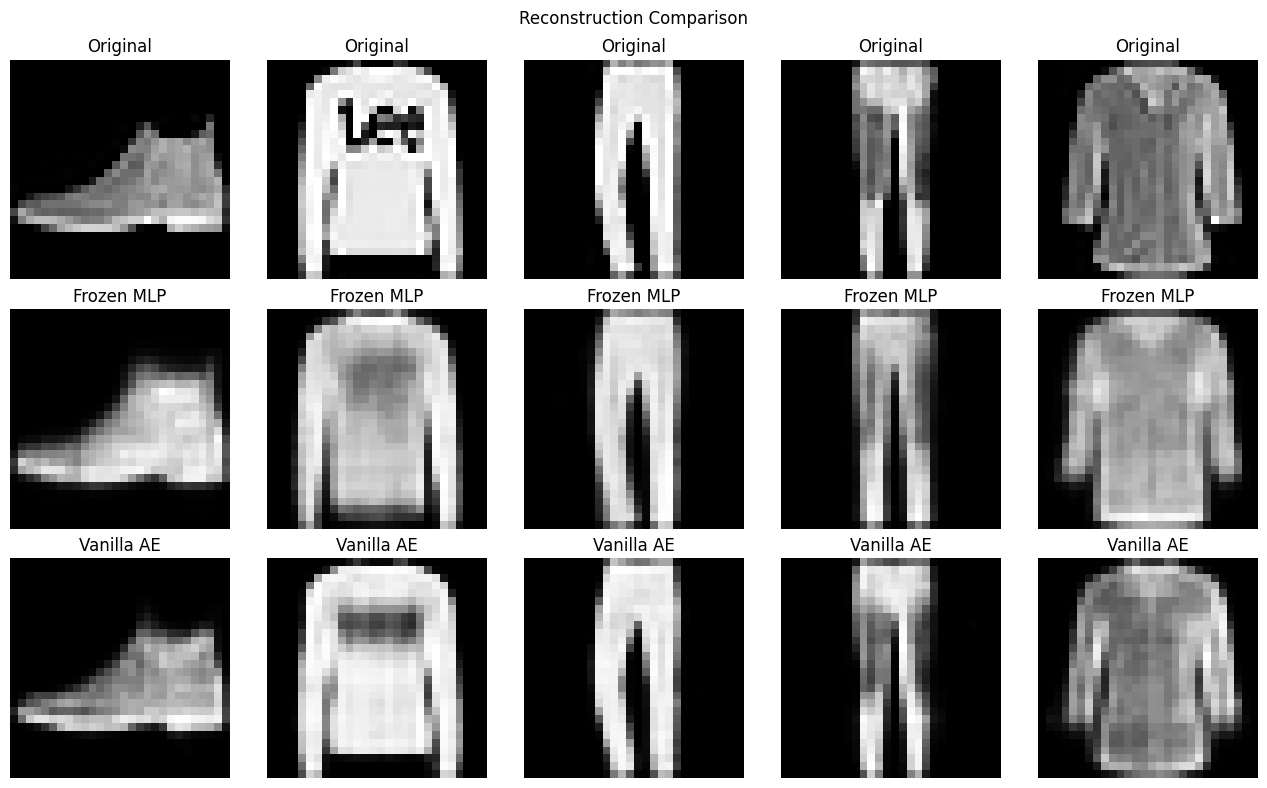

In [99]:
fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for i in range(5):

    original = x_test[i].reshape(28, 28).numpy()

    mlp_image = reconstructed_mlp[i].reshape(28, 28).numpy()

    ae_image = reconstructed_ae[i].reshape(28, 28).numpy()

    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].set_title("Original")

    axes[1, i].imshow(mlp_image, cmap="gray")
    axes[1, i].set_title("Frozen MLP")

    axes[2, i].imshow(ae_image, cmap="gray")
    axes[2, i].set_title("Vanilla AE")

    for j in range(3):
        axes[j, i].axis("off")

plt.suptitle("Reconstruction Comparison")
plt.tight_layout()
plt.show()

#Tahap 5

In [101]:
# Menghitung mean dan standard deviation
mu_z = z_test.mean(dim=0)

sigma_z = z_test.std(dim=0)

print("Mean Shape:", mu_z.shape)
print("Std Shape:", sigma_z.shape)

Mean Shape: torch.Size([64])
Std Shape: torch.Size([64])


In [102]:
# Jumlah gambar yang ingin dihasilkan
num_samples = 20

# Random Gaussian Sampling
z_rand = torch.randn(num_samples, 64) * sigma_z + mu_z

print("Random Latent Shape:", z_rand.shape)

Random Latent Shape: torch.Size([20, 64])


In [103]:
decoder.eval()

with torch.no_grad():

    z_rand = z_rand.to(device)

    generated_images = decoder(z_rand)

print("Generated Shape:", generated_images.shape)

Generated Shape: torch.Size([20, 784])


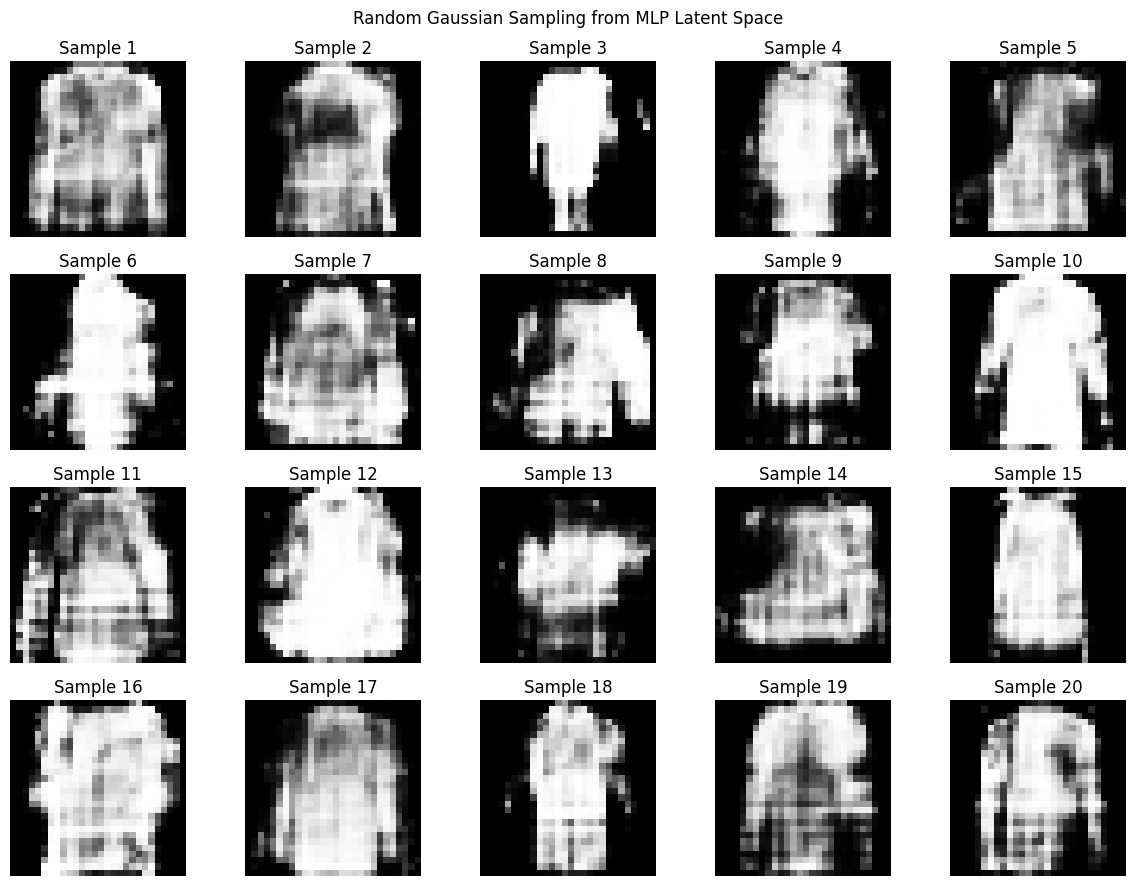

In [104]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 5, figsize=(12, 9))

for i, ax in enumerate(axes.flatten()):

    image = generated_images[i].cpu().reshape(28, 28).numpy()

    ax.imshow(image, cmap="gray")

    ax.set_title(f"Sample {i+1}")

    ax.axis("off")

plt.suptitle("Random Gaussian Sampling from MLP Latent Space")
plt.tight_layout()
plt.show()

In [105]:
print("Latent Mean:", mu_z.mean().item())
print("Latent Std:", sigma_z.mean().item())

print("Generated Pixel Mean:",
      generated_images.mean().item())

print("Generated Pixel Std:",
      generated_images.std().item())

Latent Mean: 1.685577630996704
Latent Std: 2.545280694961548
Generated Pixel Mean: 0.4020521640777588
Generated Pixel Std: 0.4042646884918213
